<a href="https://colab.research.google.com/github/sisco-velasquez/machine_learning/blob/main/logisticRegression(Early%20stage%20diabetes).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import keras
import tensorflow
import seaborn as sns

pd.options.display.max_rows = 10
pd.options.display.float_format = "{:.1f}".format

In [ ]:
diabetes = pd.read_csv('/content/diabetes_data_upload.csv')
diabetes.head()

,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [ ]:
mapping ={
    'Yes': 1,
    'No': 0,
    'Positive': 1,
    'Negative': 0,
    'Male': 1,
    'Female': 0,
    'No, borderline diabetes': 0,
    'No Info': 'Unknown',
    'No preecision': 'Unknown'
}

In [ ]:
diabetes =diabetes.replace(mapping)

/tmp/ipykernel_549/1963528892.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  diabetes =diabetes.replace(mapping)


In [ ]:
diabetes.head()

,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class,Age_Group_Under_39,Age_Group_40_49,Age_Group_50_59,Age_Group_Over_60
0,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1,False,True,False,False
1,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1,False,False,True,False
2,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1,False,True,False,False
3,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1,False,True,False,False
4,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,False,False,False,True


In [ ]:
diabetes.sample(10)

,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class,Age_Group_Under_39,Age_Group_40_49,Age_Group_50_59,Age_Group_Over_60
213,1,0,1,0,0,0,0,0,1,0,0,1,0,0,1,0,False,True,False,False
18,1,1,1,0,1,1,0,1,0,0,0,1,1,0,0,1,False,False,False,True
195,1,1,0,0,0,1,0,1,0,0,0,1,0,1,0,1,True,False,False,False
363,0,1,1,0,1,1,0,1,1,0,1,1,0,0,0,1,False,False,False,True
120,1,1,1,0,1,1,0,0,0,0,1,0,1,1,0,1,False,True,False,False
25,1,0,0,0,0,0,1,0,0,1,1,0,0,0,1,1,True,False,False,False
471,1,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,False,False,True,False
97,0,1,1,1,1,1,0,0,1,1,0,1,1,0,0,1,True,False,False,False
421,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,1,False,False,False,True
6,1,1,1,0,1,1,1,0,0,0,1,1,0,0,0,1,False,False,True,False


In [27]:
print("Minimum Age:", diabetes['Age'].min())
print("Maximum Age:", diabetes['Age'].max())

bin_edges = [0, 39, 49, 59, 100]
bin_labels = ['Under_39', '40_49', '50_59', 'Over_60']

diabetes['Age_Group'] = pd.cut(diabetes['Age'], bins=bin_edges, labels=bin_labels, right=True)
diabetes = pd.get_dummies(diabetes, columns=['Age_Group'])
diabetes= diabetes.drop('Age', axis=1)
diabetes.sample(10)

KeyError: 'Age'

In [29]:
# Automatically convert all boolean columns in your DataFrame to 1s and 0s
diabetes = diabetes.astype({col: int for col in diabetes.select_dtypes(include='bool').columns})

In [30]:
diabetes.sample(10)

,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class,Age_Group_Under_39,Age_Group_40_49,Age_Group_50_59,Age_Group_Over_60
429,1,1,1,1,1,1,0,1,0,0,1,1,1,0,1,1,0,0,1,0
484,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0
410,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
263,1,1,0,1,1,0,1,0,1,1,0,0,0,1,0,1,0,0,1,0
236,1,0,0,0,1,1,0,1,1,0,1,0,1,1,0,0,0,0,0,1
517,0,1,1,1,1,1,0,1,0,0,0,1,1,0,1,1,0,0,1,0
442,1,1,1,1,1,1,0,1,0,0,0,0,1,1,1,1,0,0,0,1
388,1,0,0,0,1,0,1,0,1,0,0,0,0,1,0,0,0,1,0,0
276,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
384,1,1,1,0,0,0,1,0,1,0,0,0,1,0,1,1,1,0,0,0


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from keras.models import Sequential
from keras.layers import Dense, Activation, Embedding, Flatten, LeakyReLU, BatchNormalization, Dropout
from keras.activations import relu, sigmoid


In [ ]:
number_sample = len(diabetes)
index_80th = round(number_sample * 0.8)
index_90th = index_80th + round(number_sample * 0.1)

shuffled_dataset = diabetes.sample(frac=1, random_state=100)
train_df = shuffled_dataset.iloc[:index_80th]
val_df = shuffled_dataset.iloc[index_80th:index_90th]
test_df = shuffled_dataset.iloc[index_90th:]

In [ ]:
scaler = StandardScaler()
scaler.fit(train_df.drop('class', axis=1))
scaled_train_df = scaler.transform(train_df.drop('class', axis=1))
scaled_val_df = scaler.transform(val_df.drop('class', axis=1))
scaled_test_df = scaler.transform(test_df.drop('class', axis=1))

In [ ]:
label_columns = ['class']
X_train = scaled_train_df
y_train = train_df[label_columns]
X_val = scaled_val_df
y_val = val_df[label_columns]
X_test = scaled_test_df
y_test = test_df[label_columns]

In [33]:
input_features = ['Pregnancies', 'PlasmaGlucose', 'DiastolicBloodPressure', 'TricepsThickness', 'SerumInsulin', 'BMI', 'DiabetesPedigree', 'Age_Group_Under_39','Age_Group_40_49','Age_Group_50_59','Age_Group_Over_60']

In [34]:
# @title Define the functions that create and train a model.
!pip install -q google-ml-edu
import ml_edu
from ml_edu.experiment import ExperimentSettings
import keras
import numpy as np
import pandas as pd

def create_model(
    settings: ml_edu.experiment.ExperimentSettings,
    metrics: list[keras.metrics.Metric],
) -> keras.Model:
  """Create and compile a simple classification model."""
  model_inputs = [
      keras.Input(name=feature, shape=(1,))
      for feature in settings.input_features
  ]
  # Use a Concatenate layer to assemble the different inputs into a single
  # tensor which will be given as input to the Dense layer.
  # For example: [input_1[0][0], input_2[0][0]]

  concatenated_inputs = keras.layers.Concatenate()(model_inputs)
  model_output = keras.layers.Dense(
      units=1, name='dense_layer', activation=keras.activations.sigmoid
  )(concatenated_inputs)
  model = keras.Model(inputs=model_inputs, outputs=model_output)
  # Call the compile method to transform the layers into a model that
  # Keras can execute.  Notice that we're using a different loss
  # function for classification than for regression.
  model.compile(
      optimizer=keras.optimizers.RMSprop(
          settings.learning_rate
      ),
      loss=keras.losses.BinaryCrossentropy(),
      metrics=metrics,
  )
  return model


def train_model(
    experiment_name: str,
    model: keras.Model,
    dataset: pd.DataFrame,
    labels: np.ndarray,
    settings: ml_edu.experiment.ExperimentSettings,
) -> ml_edu.experiment.Experiment:
  """Feed a dataset into the model in order to train it."""

  # The x parameter of keras.Model.fit can be a list of arrays, where
  # each array contains the data for one feature.
  features = {
      feature_name: np.array(dataset[feature_name])
      for feature_name in settings.input_features
  }

  history = model.fit(
      x=features,
      y=labels,
      batch_size=settings.batch_size,
      epochs=settings.number_epochs,
  )

  return ml_edu.experiment.Experiment(
      name=experiment_name,
      settings=settings,
      model=model,
      epochs=history.epoch,
      metrics_history=pd.DataFrame(history.history),
  )


print('Defined the create_model and train_model functions.')

Defined the create_model and train_model functions.


Epoch 1/60
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.6514 - auc: 0.7211 - loss: 0.6167 - precision: 0.6823 - recall: 0.8031
Epoch 2/60
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.6635 - auc: 0.7403 - loss: 0.6008 - precision: 0.6863 - recall: 0.8268
Epoch 3/60
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.6779 - auc: 0.7502 - loss: 0.5897 - precision: 0.6923 - recall: 0.8504
Epoch 4/60
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.6779 - auc: 0.7615 - loss: 0.5808 - precision: 0.6923 - recall: 0.8504
Epoch 5/60
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - accuracy: 0.6851 - auc: 0.7767 - loss: 0.5720 - precision: 0.6977 - recall: 0.8543
Epoch 6/60
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6899 - auc: 0.7836 - loss: 0.5637 - precision: 0.7023 - recall: 0.8543
Epoch 7/60
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6899 - auc: 0.7886 - loss: 0.5556 - precision: 0.7023 - recall: 0.8543 
Epoch 8/60
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 

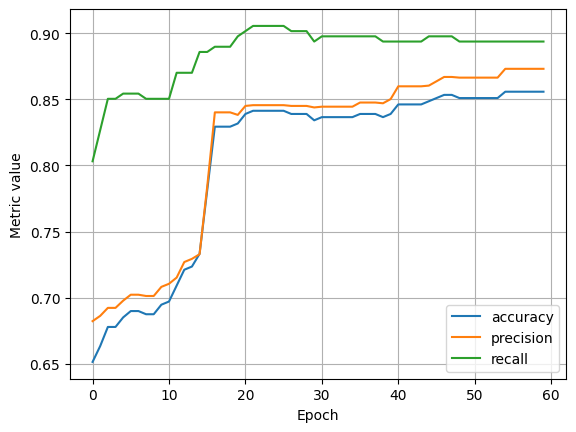

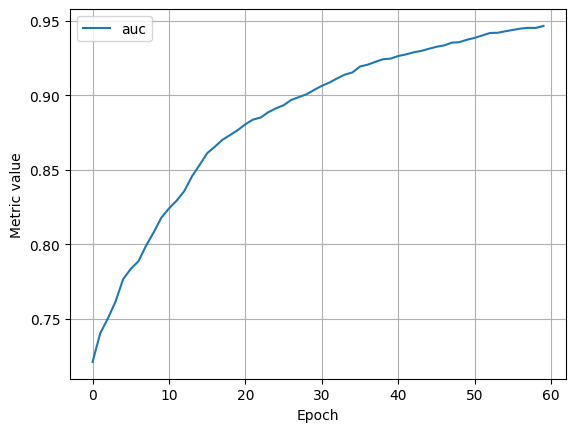

In [35]:
import ml_edu
import ml_edu.results
import keras
import pandas as pd

# 1. Define input features
input_features = [col for col in train_df.columns if col != 'class']

# 2.Convert the scaled NumPy array (X_train) BACK into a Pandas DataFrame
scaled_train_features_df = pd.DataFrame(X_train, columns=input_features)

# 3. Format labels
train_labels = y_train.values.flatten()

# 4. Define settings
settings = ml_edu.experiment.ExperimentSettings(
    learning_rate=0.001,
    number_epochs=60,
    batch_size=100,
    classification_threshold=0.35,
    input_features=input_features,
)

metrics = [
    keras.metrics.BinaryAccuracy(name='accuracy', threshold=settings.classification_threshold),
    keras.metrics.Precision(name='precision', thresholds=settings.classification_threshold),
    keras.metrics.Recall(name='recall', thresholds=settings.classification_threshold),
    keras.metrics.AUC(num_thresholds=100, name='auc'),
]

# 5. Create the model
model = create_model(settings, metrics)

# 6. Train the model using the SCALED dataframe
experiment = train_model(
    'baseline',
    model,
    scaled_train_features_df,
    train_labels,
    settings
)

# 7. Plot results
ml_edu.results.plot_experiment_metrics(experiment, ['accuracy', 'precision', 'recall'])
ml_edu.results.plot_experiment_metrics(experiment, ['auc'])

In [36]:
def compare_train_validation(experiment: ml_edu.experiment.Experiment, validation_metrics: dict[str, float]):
  print('Comparing metrics between train and validation:')
  for metric, validation_value in validation_metrics.items():
    print('------')
    print(f'Train {metric}: {experiment.get_final_metric_value(metric):.4f}')
    print(f'Validation {metric}:  {validation_value:.4f}')

# Define validation features and labels using X_val and y_val
validation_features = pd.DataFrame(X_val, columns=input_features)
validation_labels = y_val.values.flatten()

# Evaluate validation metrics
validation_metrics = experiment.evaluate(validation_features, validation_labels)
compare_train_validation(experiment, validation_metrics)

Comparing metrics between train and validation:
------
Train accuracy: 0.8558
Validation accuracy:  0.8269
------
Train auc: 0.9465
Validation auc:  0.9126
------
Train loss: 0.3443
Validation loss:  0.3999
------
Train precision: 0.8731
Validation precision:  0.8824
------
Train recall: 0.8937
Validation recall:  0.8571


In [37]:
# Define test features and labels using X_test and y_test
test_features = pd.DataFrame(X_test, columns=input_features)
test_labels = y_test.values.flatten()

# Evaluate test metrics using the correct experiment object
test_metrics_all_features = experiment.evaluate(
    test_features,
    test_labels,
)
for metric, test_value in test_metrics_all_features.items():
  print(f'Test {metric}:  {test_value:.4f}')

Test accuracy:  0.8269
Test auc:  0.9370
Test loss:  0.3693
Test precision:  0.8667
Test recall:  0.8387
